In [2]:
import pandas as pd
import numpy  as np

In [3]:
df = pd.read_excel("titanic_modified.xlsx")

In [4]:
df.sample(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Departure_Station,Travel_Alone,Family_Count,Individual_Fare
14,16,1,2,"Hewlett, Mrs. (Mary D Kingcome)",female,55.0,0,0,248706,16.000,Unknown,S,"Southampton, England",1,1,16.000
18,22,1,2,"Beesley, Mr. Lawrence",male,34.0,0,0,248698,13.000,D56,S,"Southampton, England",1,1,13.000
575,724,0,2,"Hodges, Mr. Henry Price",male,50.0,0,0,250643,13.000,Unknown,S,"Southampton, England",1,1,13.000
589,743,1,1,"Ryerson, Miss. Susan Parker ""Suzette""",female,21.0,2,2,PC 17608,262.375,B57 B59 B63 B66,C,"Cherbourg, France",0,5,52.475
328,407,0,3,"Widegren, Mr. Carl/Charles Peter",male,51.0,0,0,347064,7.750,Unknown,S,"Southampton, England",1,1,7.750


In [5]:
#One Hot Encoding
one_hot = pd.get_dummies(df["Departure_Station"], prefix="Station", drop_first=True)


In [6]:
one_hot

,"Station_Queenstown , Ireland","Station_Southampton, England",Station_Unknown
0,False,True,False
1,False,False,False
2,False,True,False
3,False,True,False
4,False,True,False
...,...,...,...
709,True,False,False
710,False,True,False
711,False,True,False
712,False,False,False


In [7]:
df.shape

(714, 16)

In [8]:
df = df.drop(df[df["Departure_Station"] == "Unknown"].index)


In [9]:
df.shape

(712, 16)

In [97]:
#One Hot Encoding
one_hot_stations_b = pd.get_dummies(df["Departure_Station"], prefix="Station", drop_first=False)


In [96]:
#One Hot Encoding
one_hot_stations = pd.get_dummies(df["Departure_Station"], prefix="Station", drop_first=True)


In [98]:
one_hot_stations_b

,"Station_Cherbourg, France","Station_Queenstown , Ireland","Station_Southampton, England"
0,False,False,True
1,True,False,False
2,False,False,True
3,False,False,True
4,False,False,True
...,...,...,...
709,False,True,False
710,False,False,True
711,False,False,True
712,True,False,False


In [14]:
one_hot_stations

,"Station_Queenstown , Ireland","Station_Southampton, England"
0,False,True
1,False,False
2,False,True
3,False,True
4,False,True
...,...,...
709,True,False
710,False,True
711,False,True
712,False,False


In [15]:
df_encoded = pd.concat([df, one_hot_stations], axis=1)

In [16]:
df_encoded.sample(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Departure_Station,Travel_Alone,Family_Count,Individual_Fare,"Station_Queenstown , Ireland","Station_Southampton, England"
82,106,0,3,"Mionoff, Mr. Stoytcho",male,28.0,0,0,349207,7.8958,Unknown,S,"Southampton, England",1,1,7.895800,False,True
341,427,1,2,"Clarke, Mrs. Charles V (Ada Maria Winfield)",female,28.0,1,0,2003,26.0000,Unknown,S,"Southampton, England",0,2,13.000000,False,True
543,687,0,3,"Panula, Mr. Jaako Arnold",male,14.0,4,1,3101295,39.6875,Unknown,S,"Southampton, England",0,6,6.614583,False,True
492,624,0,3,"Hansen, Mr. Henry Damsgaard",male,21.0,0,0,350029,7.8542,Unknown,S,"Southampton, England",1,1,7.854200,False,True
700,876,1,3,"Najib, Miss. Adele Kiamie ""Jane""",female,15.0,0,0,2667,7.2250,Unknown,C,"Cherbourg, France",1,1,7.225000,False,False


In [17]:
one_hot_gender = pd.get_dummies(df["Sex"], prefix="Gender", drop_first=True)

In [18]:
one_hot_gender

,Gender_male
0,True
1,False
2,False
3,False
4,True
...,...
709,False
710,True
711,False
712,True


In [19]:
df_encoded = pd.concat([df_encoded, one_hot_gender], axis=1)

In [101]:
df_encoded.sample(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Departure_Station,Travel_Alone,Family_Count,Individual_Fare,"Station_Queenstown , Ireland","Station_Southampton, England",Gender_male,Cabin_encoded
146,184,1,2,"Becker, Master. Richard F",male,1.0,2,1,230136,39.0000,F4,S,"Southampton, England",0,4,9.750000,False,True,True,39.000000
51,69,1,3,"Andersson, Miss. Erna Alexandra",female,17.0,4,2,3101281,7.9250,Unknown,S,"Southampton, England",0,7,1.132143,False,True,False,19.306222
321,400,1,2,"Trout, Mrs. William H (Jessie L)",female,28.0,0,0,240929,12.6500,Unknown,S,"Southampton, England",1,1,12.650000,False,True,False,19.306222
255,319,1,1,"Wick, Miss. Mary Natalie",female,31.0,0,2,36928,164.8667,C7,S,"Southampton, England",0,3,54.955567,False,True,False,164.866700
344,431,1,1,"Bjornstrom-Steffansson, Mr. Mauritz Hakan",male,28.0,0,0,110564,26.5500,C52,S,"Southampton, England",1,1,26.550000,False,True,True,26.550000


In [ ]:
#first lets target encode the cabin column with fare


In [22]:
# Compute mean fare per cabin
cabin_target = df_encoded.groupby("Cabin")["Fare"].mean()

In [102]:
cabin_target

Cabin
A10        40.125000
A16        39.600000
A20        56.929200
A23        30.000000
A24        50.495800
             ...    
F33        11.333333
F4         39.000000
G6         13.581250
T          35.500000
Unknown    19.306222
Name: Fare, Length: 134, dtype: float64

In [24]:
df_encoded["Cabin_encoded"] = df_encoded["Cabin"].map(cabin_target)

In [25]:
df_encoded.sample(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Departure_Station,Travel_Alone,Family_Count,Individual_Fare,"Station_Queenstown , Ireland","Station_Southampton, England",Gender_male,Cabin_encoded
59,79,1,2,"Caldwell, Master. Alden Gates",male,0.83,0,2,248738,29.0000,Unknown,S,"Southampton, England",0,3,9.666667,False,True,True,19.306222
188,234,1,3,"Asplund, Miss. Lillian Gertrud",female,5.00,4,2,347077,31.3875,Unknown,S,"Southampton, England",0,7,4.483929,False,True,False,19.306222
652,817,0,3,"Heininen, Miss. Wendla Maria",female,23.00,0,0,STON/O2. 3101290,7.9250,Unknown,S,"Southampton, England",1,1,7.925000,False,True,False,19.306222
387,487,1,1,"Hoyt, Mrs. Frederick Maxfield (Jane Anne Forby)",female,35.00,1,0,19943,90.0000,C93,S,"Southampton, England",0,2,45.000000,False,True,False,90.000000
394,495,0,3,"Stanley, Mr. Edward Roland",male,21.00,0,0,A/4 45380,8.0500,Unknown,S,"Southampton, England",1,1,8.050000,False,True,True,19.306222


In [26]:
#now to separate the columns we need.
df_final = df_encoded.drop(columns=["PassengerId", "Name", "Ticket", "Cabin", "Sex", "Departure_Station", "Embarked"])

In [28]:
df_final.sample(5)

,Survived,Pclass,Age,SibSp,Parch,Fare,Travel_Alone,Family_Count,Individual_Fare,"Station_Queenstown , Ireland","Station_Southampton, England",Gender_male,Cabin_encoded
697,0,1,33.0,0,0,5.0000,1,1,5.0000,False,True,True,258.664600
138,1,3,1.0,1,1,11.1333,0,3,3.7111,False,True,False,19.306222
445,0,3,40.0,0,0,7.8958,1,1,7.8958,False,True,True,19.306222
303,0,3,19.0,0,0,7.7750,1,1,7.7750,False,True,True,19.306222
250,0,3,28.0,0,0,7.8958,1,1,7.8958,False,True,True,19.306222


In [29]:
from sklearn.model_selection import train_test_split

In [31]:
from sklearn.preprocessing import MinMaxScaler

In [30]:
x = df_final.drop(columns=["Survived"])
y = df_final["Survived"]

In [105]:
x.shape

(712, 12)

In [53]:
y

0      0
1      1
2      1
3      1
4      0
      ..
709    0
710    0
711    1
712    1
713    0
Name: Survived, Length: 712, dtype: int64

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [33]:
x_train.shape

(569, 12)

In [104]:
x_train[0:5]

,Pclass,Age,SibSp,Parch,Fare,Travel_Alone,Family_Count,Individual_Fare,"Station_Queenstown , Ireland","Station_Southampton, England",Gender_male,Cabin_encoded
376,2,33.0,1,2,27.7500,0,4,6.9375,False,True,False,19.306222
345,2,42.0,1,0,26.0000,0,2,13.0000,False,True,False,19.306222
527,2,25.0,0,0,13.0000,1,1,13.0000,False,True,True,19.306222
24,1,40.0,0,0,27.7208,1,1,27.7208,False,False,True,19.306222
235,1,19.0,1,0,91.0792,0,2,45.5396,False,False,False,91.079200


In [106]:
y.shape

(712,)

In [34]:
y_train.shape

(569,)

In [35]:
x_test.shape

(143, 12)

In [36]:
y_test.shape

(143,)

In [37]:
scaler = MinMaxScaler()

In [38]:
x_train_scaled = scaler.fit_transform(x_train)

In [39]:
x_test_scaled = scaler.transform(x_test)

In [ ]:
x_train_scaled[0:5]

array([[0.5       , 0.40939935, 0.2       , 0.33333333, 0.05416439,
        0.        , 0.42857143, 0.0135411 , 0.        , 1.        ,
        0.        , 0.07340769],
       [0.5       , 0.52249309, 0.2       , 0.        , 0.05074862,
        0.        , 0.14285714, 0.02537431, 0.        , 1.        ,
        0.        , 0.07340769],
       [0.5       , 0.30887158, 0.        , 0.        , 0.02537431,
        1.        , 0.        , 0.02537431, 0.        , 1.        ,
        1.        , 0.07340769],
       [0.        , 0.49736115, 0.        , 0.        , 0.0541074 ,
        1.        , 0.        , 0.0541074 , 0.        , 0.        ,
        1.        , 0.07340769],
       [0.        , 0.23347575, 0.2       , 0.        , 0.17777476,
        0.        , 0.14285714, 0.08888738, 0.        , 0.        ,
        0.        , 0.34630875]])

In [43]:
x_test_scaled[0:5]

array([[0.        , 0.2963056 , 0.        , 0.        , 0.13526459,
        1.        , 0.        , 0.13526459, 0.        , 0.        ,
        0.        , 0.2634981 ],
       [0.        , 0.67328474, 0.2       , 0.        , 0.15276642,
        0.        , 0.14285714, 0.07638321, 0.        , 0.        ,
        0.        , 0.29759202],
       [0.        , 0.6481528 , 0.2       , 0.16666667, 0.15546645,
        0.        , 0.28571429, 0.05182215, 0.        , 1.        ,
        1.        , 0.30285171],
       [0.        , 0.22090978, 0.4       , 0.33333333, 0.51212189,
        0.        , 0.57142857, 0.10242438, 0.        , 0.        ,
        0.        , 0.99762357],
       [0.5       , 0.33400352, 0.        , 0.        , 0.05074862,
        1.        , 0.        , 0.05074862, 0.        , 1.        ,
        1.        , 0.07340769]])

In [44]:
x_train_scaled.shape

(569, 12)

In [54]:
x_test_scaled.shape

(143, 12)

In [55]:
import seaborn as sns 
#Outlier Handling
df_final["Age"]

0      22.0
1      38.0
2      26.0
3      35.0
4      35.0
       ... 
709    39.0
710    27.0
711    19.0
712    26.0
713    32.0
Name: Age, Length: 712, dtype: float64

<Axes: ylabel='Age'>

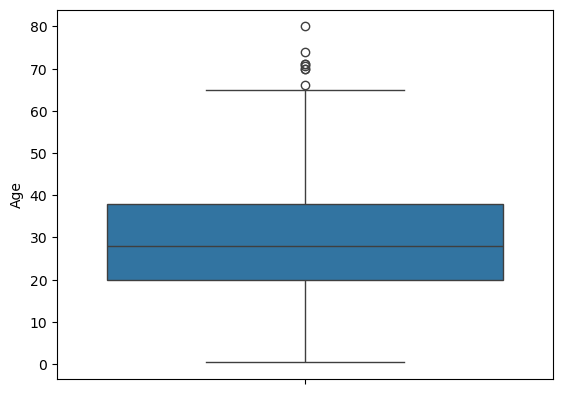

In [56]:
sns.boxplot(df_final["Age"])

<Axes: ylabel='Fare'>

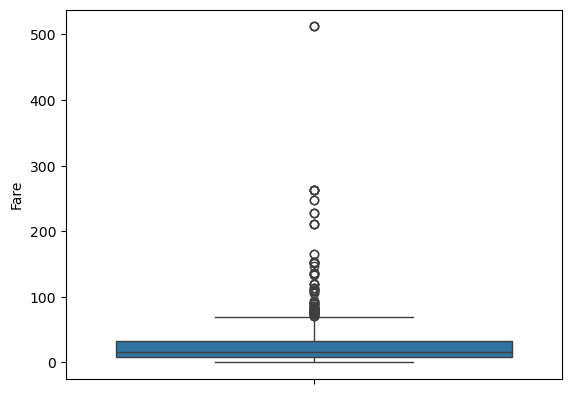

In [57]:
sns.boxplot(df_final["Fare"])

<Axes: ylabel='Individual_Fare'>

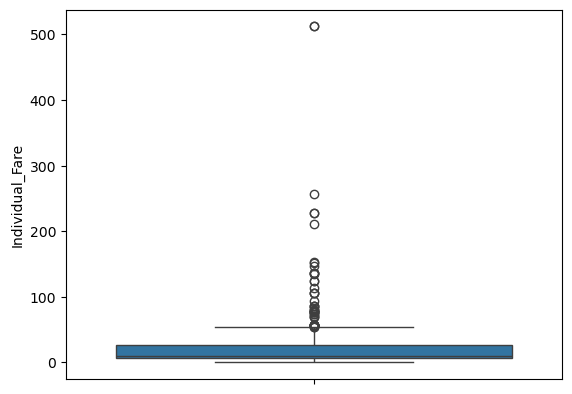

In [58]:
sns.boxplot(df_final["Individual_Fare"])

In [59]:
Q1 = df_final["Age"].quantile(0.25)
Q3 = df_final["Age"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR


In [ ]:
outliers = df_final[(df_final["Age"] < lower_bound) or (df_final["Age"] > upper_bound)]
outliers

,Survived,Pclass,Age,SibSp,Parch,Fare,Travel_Alone,Family_Count,Individual_Fare,"Station_Queenstown , Ireland","Station_Southampton, England",Gender_male,Cabin_encoded
25,0,2,66.0,0,0,10.5000,1,1,10.500000,False,True,True,19.306222
74,0,1,71.0,0,0,34.6542,1,1,34.654200,False,False,True,34.654200
91,0,3,70.5,0,0,7.7500,1,1,7.750000,True,False,True,19.306222
393,0,1,71.0,0,0,49.5042,1,1,49.504200,False,False,True,19.306222
498,1,1,80.0,0,0,30.0000,1,1,30.000000,False,True,True,30.000000
531,0,2,70.0,0,0,10.5000,1,1,10.500000,False,True,True,19.306222
592,0,1,70.0,1,1,71.0000,0,3,23.666667,False,True,True,71.000000
679,0,3,74.0,0,0,7.7750,1,1,7.775000,False,True,True,19.306222


In [77]:
len(outliers)

8

In [73]:
df_final_outliers = df_final[(df_final["Age"] >= lower_bound) & (df_final["Age"] <= upper_bound)]


In [74]:
df_final_outliers.shape

(704, 13)

In [75]:
df_final.shape

(712, 13)

C:\Users\aitza\AppData\Local\Temp\ipykernel_19336\1100395041.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df_final["Age"])


<Axes: xlabel='Age', ylabel='Density'>

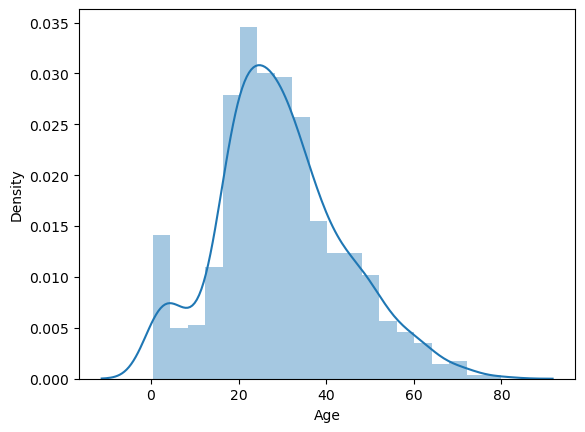

In [79]:
sns.distplot(df_final["Age"])

C:\Users\aitza\AppData\Local\Temp\ipykernel_19336\575999189.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df_final_outliers["Age"])


<Axes: xlabel='Age', ylabel='Density'>

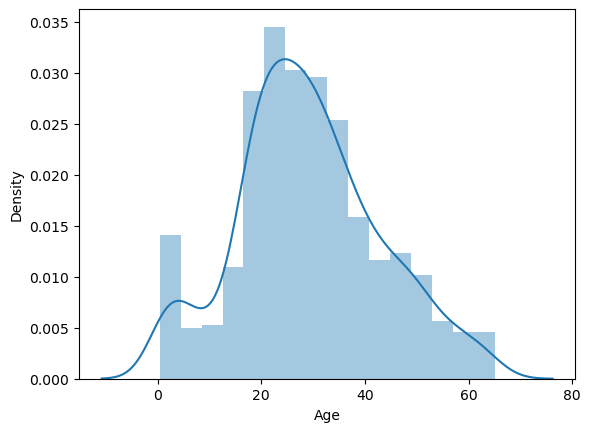

In [80]:
sns.distplot(df_final_outliers["Age"])

In [81]:
Q1 = df_final["Fare"].quantile(0.25)
Q3 = df_final["Fare"].quantile(0.75)
IQR = Q3 - Q1

fare_lower_bound = Q1 - 1.5 * IQR
fare_upper_bound = Q3 + 1.5 * IQR


In [83]:
df_final_outliers_fare = df_final[(df_final["Fare"] >= fare_lower_bound) & (df_final["Fare"] <= fare_upper_bound)]


C:\Users\aitza\AppData\Local\Temp\ipykernel_19336\2825640620.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df_final["Fare"])


<Axes: xlabel='Fare', ylabel='Density'>

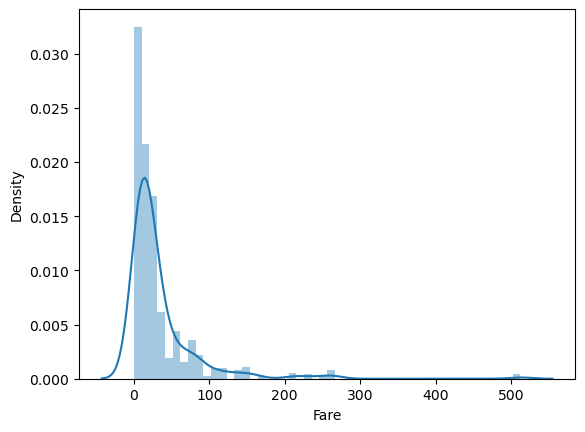

In [85]:
sns.distplot(df_final["Fare"])

C:\Users\aitza\AppData\Local\Temp\ipykernel_19336\1070397962.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df_final_outliers_fare["Fare"])


<Axes: xlabel='Fare', ylabel='Density'>

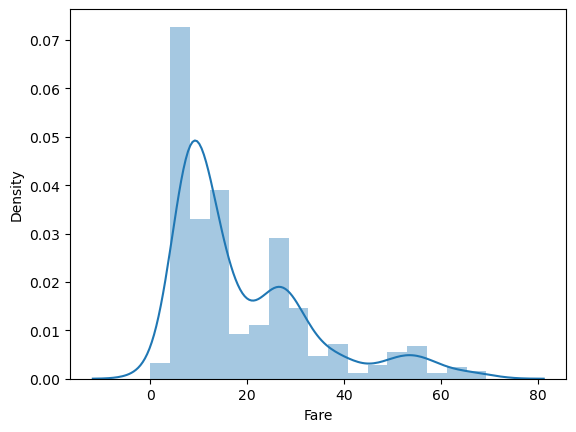

In [87]:
sns.distplot(df_final_outliers_fare["Fare"])

<Axes: ylabel='Age'>

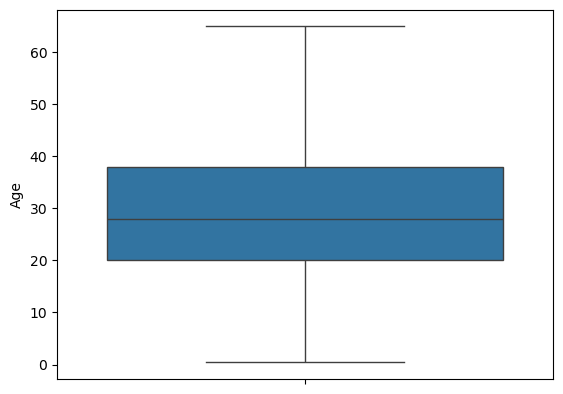

In [88]:
sns.boxplot(df_final_outliers["Age"])

<Axes: ylabel='Fare'>

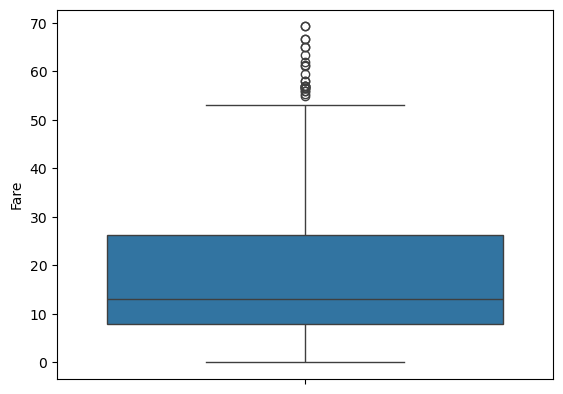

In [89]:
sns.boxplot(df_final_outliers_fare["Fare"])